- **Execution Environment:** Google Colab
- **Python:** 3.13.16
- **pandas:** 2.2.3
- **matplotlib:** 3.10.0
- **scipy:** 1.16.3
- **statsmodels:** 0.15.0

## setting up

In [30]:
#package
import os
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [31]:
#set current directrory
# os.chdir("")

In [32]:
#read data
#※data ignored as a public repository
df = pd.read_stata("data/cd15.dta")

In [33]:
df.columns

Index(['days_to_21', 'ill_drugs_r', 'dui_r', 'liquor_laws_r', 'violent_r',
       'murder_r', 'manslaughter_r', 'rape_r', 'robbery_r',
       'aggravated_assault_r', 'ot_assault_r', 'property_r', 'weapons_r',
       'county_ordinance_r', 'traffic_violations_r', 'hit_run_reckl_driv_r',
       'alcohol_r', 'all_r', 'other_r', 'combined_oth_r', 'drunk_risk_r'],
      dtype='object')

In [34]:
#check days to 21
df['days_to_21'].describe()

,days_to_21
count,1460.000000
mean,-0.500000
std,421.610009
min,-730.000000
25%,-365.250000
50%,-0.500000
75%,364.250000
max,729.000000


In [35]:
#restrict -730<=t<=730
print(f"Before restrict: {len(df)}")
df = df[(df['days_to_21'] >= -730) & (df['days_to_21'] < 730)]
print(f"After restrict: {len(df)}")

Before restrict: 1460
After restrict: 1460


##A1. Reproduce the structure of Table 1

In [36]:
#filtered all variables non-missing
y_vars = ['all_r', 'violent_r', 'property_r', 'ill_drugs_r', 'alcohol_r', 'other_r']

df_analysis = df.dropna(subset=y_vars).copy()

print(f"Before dropna: {len(df)}")
print(f"After dropna: {len(df_analysis)}")

Before dropna: 1460
After dropna: 1460


In [37]:
#create variables for regression
df_analysis['D'] = (df_analysis['days_to_21'] >= 0).astype(int)

for j in [19, 20, 21, 22]:
    c = 365 * (j - 21)
    df_analysis[f'B{j}'] = (df_analysis['days_to_21'] == c).astype(int)
    df_analysis[f'A{j}'] = (df_analysis['days_to_21'] == c + 1).astype(int)

In [38]:
#regression with hc1
rhs = (
    'D + days_to_21 + I(days_to_21**2)'
    ' + D:days_to_21 + D:I(days_to_21**2)'
    ' + B19 + A19 + B20 + A20 + B21 + A21 + B22 + A22'
)

results = {}
for y in y_vars:
    results[y] = smf.ols(f'{y} ~ {rhs}', data=df_analysis).fit(cov_type='HC1')
    print(results[y].summary())

                            OLS Regression Results                            
Dep. Variable:                  all_r   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.766
Method:                 Least Squares   F-statistic:                 1.521e+05
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        07:51:43   Log-Likelihood:                -6790.0
No. Observations:                1460   AIC:                         1.361e+04
Df Residuals:                    1446   BIC:                         1.368e+04
Df Model:                          13                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             1542.5969 

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 13, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 13, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 13, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 13, but rank is 6
  res = self.wald_test(


                            OLS Regression Results                            
Dep. Variable:             property_r   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.954
Method:                 Least Squares   F-statistic:                 1.098e+07
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        07:51:43   Log-Likelihood:                -5167.0
No. Observations:                1460   AIC:                         1.036e+04
Df Residuals:                    1446   BIC:                         1.044e+04
Df Model:                          13                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              224.3320 

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 13, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 13, but rank is 6
  res = self.wald_test(


In [39]:
#transrate tabele for latex

col_names = {
    'all_r': 'All',
    'violent_r': 'Violent',
    'property_r': 'Property',
    'ill_drugs_r': 'Illegal Drugs',
    'alcohol_r': 'Alcohol Related',
    'other_r': 'Other',
}

tab = pd.DataFrame(
    index=['Increase at 21', '', 'Rate just under 21', 'N'],
    columns=list(col_names.values()),
)

for y, name in col_names.items():
    r = results[y]
    tab.loc['Increase at 21', name] = f"{r.params['D']:.1f}"
    tab.loc['', name] = f"({r.bse['D']:.1f})"
    tab.loc['Rate just under 21', name] = f"{r.params['Intercept']:,.1f}"
    tab.loc['N', name] = f"{int(r.nobs):,}"

latex = tab.to_latex(column_format='l' + 'c' * len(col_names))
print(latex)

\begin{tabular}{lcccccc}
\toprule
 & All & Violent & Property & Illegal Drugs & Alcohol Related & Other \\
\midrule
Increase at 21 & 90.8 & 10.9 & 5.0 & 5.7 & 18.5 & 50.7 \\
 & (4.3) & (1.1) & (1.3) & (1.3) & (2.0) & (2.6) \\
Rate just under 21 & 1,542.6 & 151.4 & 224.3 & 219.2 & 394.6 & 553.1 \\
N & 1,460 & 1,460 & 1,460 & 1,460 & 1,460 & 1,460 \\
\bottomrule
\end{tabular}



## A3. Draw an RD figure.

In [40]:
#caliculate fitted value
pred_df = pd.DataFrame({'days_to_21': df_analysis['days_to_21'].values})
pred_df['D'] = (pred_df['days_to_21'] >= 0).astype(int)

for j in [19, 20, 21, 22]:
    pred_df[f'B{j}'] = 0
    pred_df[f'A{j}'] = 0

pred_df['fitted_all'] = results['all_r'].predict(pred_df)

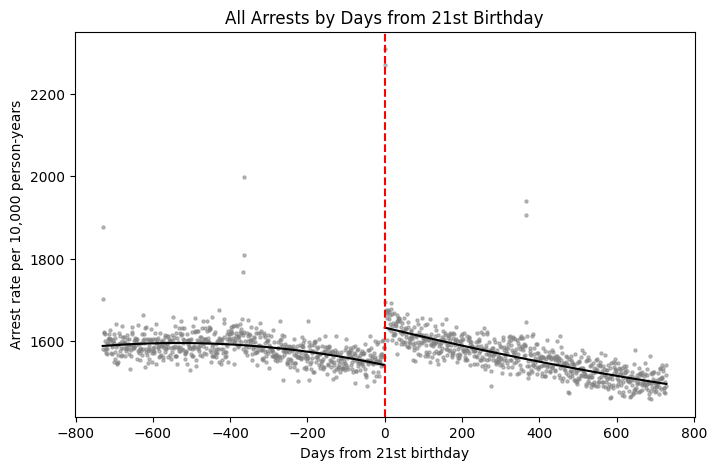

In [41]:
#draw figure
left = pred_df['days_to_21'] < 0
right = pred_df['days_to_21'] >= 0

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df_analysis['days_to_21'], df_analysis['all_r'], s=5, color='gray', alpha=0.5)

ax.plot(pred_df.loc[left, 'days_to_21'], pred_df.loc[left, 'fitted_all'], color='black')
ax.plot(pred_df.loc[right, 'days_to_21'], pred_df.loc[right, 'fitted_all'], color='black')

ax.axvline(0, color='red', linestyle='--')

ax.set_xlabel('Days from 21st birthday')
ax.set_ylabel('Arrest rate per 10,000 person-years')
ax.set_title('All Arrests by Days from 21st Birthday')

plt.show()